[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E5%85%A8%E6%96%B9%E9%9D%A2%E5%88%86%E6%9E%90/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E6%9C%9F%E6%9C%AB%E5%AF%A6%E6%88%B0_%E5%8F%B0%E9%90%B52023%E9%80%9A%E5%8B%A4%E7%AB%99%E8%88%87%E8%A7%80%E5%85%89%E7%AB%99.ipynb)

# 🚆 期末實戰：台鐵 2023——誰是通勤站？誰是觀光站？

> 🧋 **情境**：這次不是茶語時光，而是**真實的政府開放資料**：台鐵 2023 年 241 個車站、每天的進出站人數。你是交通部委託的分析師，要回答四個問題：①哪些車站是「上班族通勤站」、哪些是「假日觀光站」？②春節期間，哪些車站人潮暴增、哪些變成空城？③哪幾天全台運量最低，發生了什麼事？④寫一份給長官的三點摘要。這是一個完整的分析流程，每一步都附上「指揮 AI」的範本，請試著自己完成，再對照參考程式。

| 素材檔案 | 內容 |
| --- | --- |
| `課程原始資料/每日各站進出站人數2023.csv` | 台鐵 2023 年每日各站進出站人數（真實資料，86,609 筆） |
| `台鐵車站資訊.csv` | 車站代碼與站名、地址對照表 |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

> ℹ️ 本資料為政府開放資料，與課程虛構的「茶語時光」無關。本資料夾另附老師的完整分析 Notebook：`課程原始資料/站點2023年進出分析.ipynb`。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '課程原始資料/每日各站進出站人數2023.csv',
    '台鐵車站資訊.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E5%85%A8%E6%96%B9%E9%9D%A2%E5%88%86%E6%9E%90/%E5%85%A8%E6%96%B9%E9%9D%A2%E5%88%86%E6%9E%90_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['課程原始資料/每日各站進出站人數2023.csv', '台鐵車站資訊.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援 ---
# 使用 mplfonts 自動套用思源黑體，避免圖表中文出現亂碼或方塊字
%pip install -q mplfonts
!mplfonts init

from mplfonts import use_font
use_font("Noto Sans CJK SC")

## 第 1 步：載入、合併站名、健康檢查

> 🤖 **指揮 AI**：「這份 CSV 的欄位是 trnOpDate（YYYYMMDD 整數）、staCode（車站代碼）、gateInComingCnt、gateOutGoingCnt。請讀取後與車站資訊表用代碼合併出站名，並做資料健康檢查（筆數、日期範圍、缺值、合併不到的代碼）。」

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('課程原始資料/每日各站進出站人數2023.csv')
stations = pd.read_csv('台鐵車站資訊.csv', usecols=['stationCode', 'stationName'])

df = df.merge(stations, left_on='staCode', right_on='stationCode', how='left', indicator=True)
print('筆數：', len(df), '｜車站數：', df['staCode'].nunique())
print('合併結果：\n', df['_merge'].value_counts())
print('缺值：\n', df.isnull().sum())

df['日期'] = pd.to_datetime(df['trnOpDate'].astype(str), format='%Y%m%d')
df['總運量'] = df['gateInComingCnt'] + df['gateOutGoingCnt']
df['假日'] = df['日期'].dt.dayofweek >= 5                               # 星期六、日
print('日期範圍：', df['日期'].min().date(), '～', df['日期'].max().date())

筆數： 86609 ｜車站數： 241
合併結果：
 _merge
both          86609
left_only         0
right_only        0
Name: count, dtype: int64
缺值：
 trnOpDate          0
staCode            0
gateInComingCnt    0
gateOutGoingCnt    0
stationCode        0
stationName        0
_merge             0
dtype: int64
日期範圍： 2023-01-01 ～ 2023-12-31


## 第 2 步：通勤站 vs. 觀光站——平日 ÷ 假日比

**分析設計**：每站計算「平日平均運量 ÷ 假日平均運量」。
- 比值 **> 1**：平日人多 → 上班上學的**通勤站**
- 比值 **< 1**：假日人多 → **觀光、休閒或返鄉站**

為了避免小站的數字不穩定，只看日均運量 3,000 人次以上的車站。

> 🤖 **指揮 AI**：「請計算每個車站平日與假日的平均總運量，只保留日均 3,000 以上的車站，算出平日÷假日比，列出最像通勤站與最像觀光站的各 8 站，並畫成水平長條圖。」

▶ 最像「通勤站」：
                 平日平均     假日平均  平日÷假日
stationName                         
汐科           25343.0  11344.0   2.23
五堵            4399.0   3056.0   1.44
百福            5284.0   3836.0   1.38
松山           35965.0  26341.0   1.37
北新竹           5207.0   3788.0   1.37
七堵           12550.0   9429.0   1.33
八堵            4771.0   3671.0   1.30
汐止           21624.0  16865.0   1.28

▶ 最像「觀光站」：
                 平日平均     假日平均  平日÷假日
stationName                         
臺中           41777.0  68419.0   0.61
大甲            4691.0   7024.0   0.67
新烏日          12873.0  19007.0   0.68
沙崙            5012.0   7393.0   0.68
沙鹿            4613.0   6640.0   0.69
豐原           13655.0  18774.0   0.73
潭子            4142.0   5586.0   0.74
礁溪            3332.0   4519.0   0.74


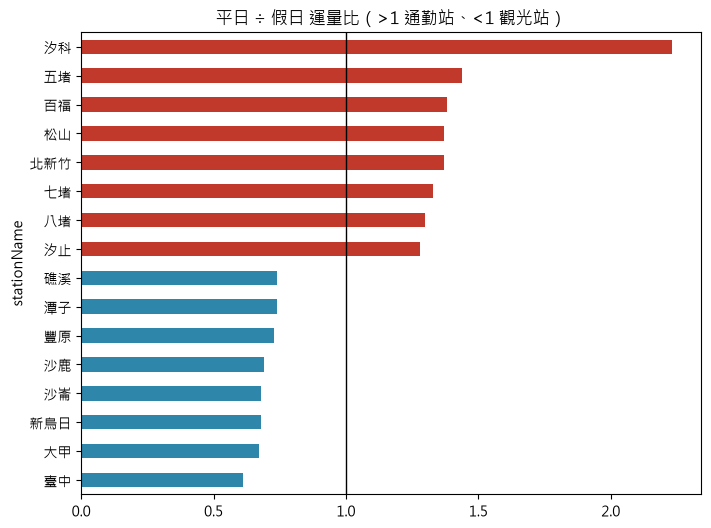

In [4]:
wk = df.pivot_table(index='stationName', columns='假日', values='總運量', aggfunc='mean')
wk.columns = ['平日平均', '假日平均']
wk = wk[wk.mean(axis=1) >= 3000]
wk['平日÷假日'] = (wk['平日平均'] / wk['假日平均']).round(2)

ranked = wk.sort_values('平日÷假日')
print('▶ 最像「通勤站」：\n', ranked.tail(8)[::-1].round({'平日平均': 0, '假日平均': 0}))
print('\n▶ 最像「觀光站」：\n', ranked.head(8).round({'平日平均': 0, '假日平均': 0}))

pick = pd.concat([ranked.head(8), ranked.tail(8)])['平日÷假日']
ax = pick.plot.barh(figsize=(8, 6), color=['#2E86AB' if v < 1 else '#C0392B' for v in pick])
ax.axvline(1, color='black', linewidth=1)
ax.set_title('平日 ÷ 假日 運量比（>1 通勤站、<1 觀光站）')
plt.show()

> 💡 **看懂結果**：
> - **汐科站**平日人潮是假日的 2 倍以上——旁邊就是汐止科學園區，完全是上班族的打卡鐘；南港、松山、汐止也都是北部的通勤大站。
> - **臺中、大甲、礁溪**則是假日比較多人：臺中是觀光購物與轉乘大站，大甲有知名的鎮瀾宮，礁溪是溫泉勝地。
> - 這個簡單的比值，就能幫台鐵決定：**通勤站平日加開班次、觀光站假日加派人力**。

## 第 3 步：春節返鄉潮——哪些站暴增、哪些變空城？

**分析設計**：2023 年春節連假是 1/20～1/29。用「連假期間日均運量 ÷ 1/2～1/17 的日均運量」看變化倍數。

> 🤖 **指揮 AI**：「請比較 2023 年 1/20–1/29 春節連假與 1/2–1/17 的各站日均總運量，計算倍數，列出成長最多與減少最多的車站（只看日均 3,000 以上）。」

In [5]:
cny = df[df['日期'].between('2023-01-20', '2023-01-29')].groupby('stationName')['總運量'].mean()
base = df[df['日期'].between('2023-01-02', '2023-01-17')].groupby('stationName')['總運量'].mean()
change = (cny / base)[base >= 3000].sort_values()

print('▶ 春節人潮暴增：\n', change.tail(8)[::-1].round(2))
print('\n▶ 春節變成空城：\n', change.head(8).round(2))

▶ 春節人潮暴增：
 stationName
大甲     2.70
潮州     2.02
臺東     1.92
礁溪     1.69
臺中     1.67
花蓮     1.64
新左營    1.63
沙鹿     1.53
Name: 總運量, dtype: float64

▶ 春節變成空城：
 stationName
汐科     0.41
浮洲     0.57
大湖     0.59
北新竹    0.60
五堵     0.63
百福     0.64
汐止     0.69
松山     0.70
Name: 總運量, dtype: float64


> 💡 **看懂結果**：大甲站春節期間人潮是平時的 **2.7 倍**（春節進香人潮），臺東、潮州、花蓮等東部與南部車站也大幅成長——這就是**返鄉潮**；相反地，汐科、南港等通勤站運量剩不到一半。**資料完全反映了「台北人春節回家」的現象。**

## 第 4 步：全台運量最低與最高的日子

> 🤖 **指揮 AI**：「請算出全台每日總運量，畫出折線圖與 7 日移動平均，並列出運量最低與最高的 5 天，提醒我可以對照當天的新聞或節日。」

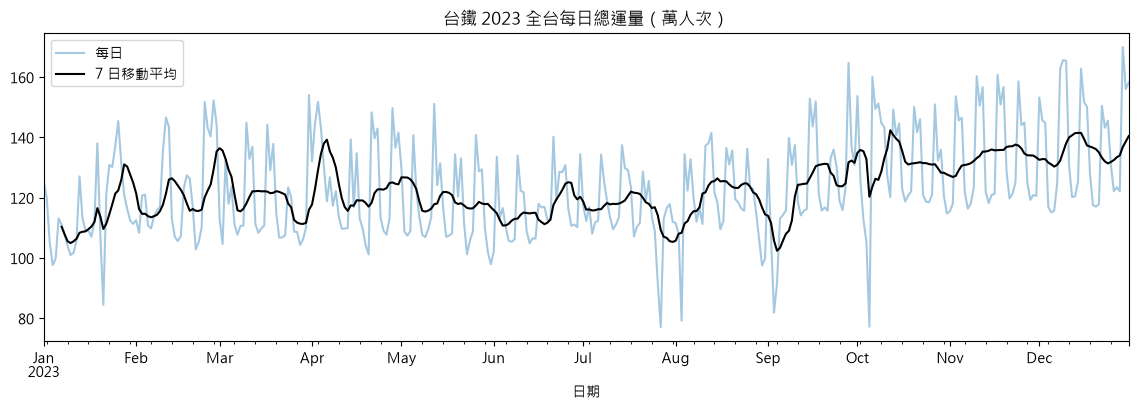

▶ 運量最低的 5 天：
 日期
2023-07-27    770642
2023-10-05    771840
2023-08-03    791638
2023-09-03    818376
2023-01-21    844804
Name: 總運量, dtype: int64

▶ 運量最高的 5 天：
 日期
2023-12-29    1699548
2023-12-09    1656316
2023-12-10    1653966
2023-09-28    1647300
2023-12-08    1628392
Name: 總運量, dtype: int64


In [6]:
daily = df.groupby('日期')['總運量'].sum()
ax = (daily / 10000).plot(figsize=(14, 4), alpha=0.4, label='每日')
(daily.rolling(7).mean() / 10000).plot(ax=ax, color='black', label='7 日移動平均')
ax.set_title('台鐵 2023 全台每日總運量（萬人次）')
ax.legend()
plt.show()

print('▶ 運量最低的 5 天：\n', daily.nsmallest(5))
print('\n▶ 運量最高的 5 天：\n', daily.nlargest(5))

> 💡 **看懂結果**：運量最低的日子集中在 7/27、10/5、8/3、9/3 等——對照新聞，都是颱風來襲、多地停班停課的日子（杜蘇芮、小犬、卡努、海葵颱風）；運量最高的則多是連假前的星期五與 12 月的週末。**異常值往往藏著真實的故事，不要急著把它刪掉。**

## 第 5 步：寫給長官的三點摘要

> 🤖 **指揮 AI**：「根據以上分析結果（貼上第 2～4 步的輸出），請幫我寫一份給交通部長官的摘要，三點以內，每點包含一個關鍵數字與一個具體建議，語氣正式、繁體中文。」

**範例摘要**（請改寫成你自己的版本）：
1. **通勤與觀光需求分明**：汐科站平日運量是假日的 2 倍以上，臺中、大甲、礁溪則是假日較多。建議通勤站平日尖峰加開區間車，觀光站假日加派站務人力。
2. **春節返鄉潮集中在南部與東部**：大甲、潮州、臺東、花蓮等站春節日均運量為平時的 1.6～2.7 倍。建議連假前加開東部與南部對號列車。
3. **颱風是最大的營運風險**：全年運量最低的日子都是颱風日，全台運量可掉到平時的一半左右。建議建立颱風應變的動態調度機制。

---

## ✍️ 延伸挑戰

1. 用「淨流量」（進站 − 出站）找出早上「人潮流入」最多的車站——它們是住宅區還是商業區？（提示：本資料只有每日加總，可以比較全年平均淨流量的正負）
2. 把第 2 步的門檻從 3,000 改成 1,000，名單有什麼變化？小站的比值為什麼比較不穩定？
3. 選一個你家附近的車站，畫出它 2023 年每月的平均運量，寫下你觀察到的三件事。

## 🔑 延伸挑戰參考程式

全年平均淨流量最負（出站多於進站）：
 stationName
枋野   -1064.0
桃園    -763.0
南港    -655.0
成功    -463.0
臺南    -463.0
Name: 淨流量, dtype: float64

全年平均淨流量最正（進站多於出站）：
 stationName
五堵      388.0
基隆      409.0
追分      444.0
新烏日     510.0
臺北     1019.0
Name: 淨流量, dtype: float64

門檻 1,000 時的通勤站前 5 名：
 stationName
和平    3.29
汐科    2.23
柳營    1.59
南科    1.44
五堵    1.44
dtype: float64


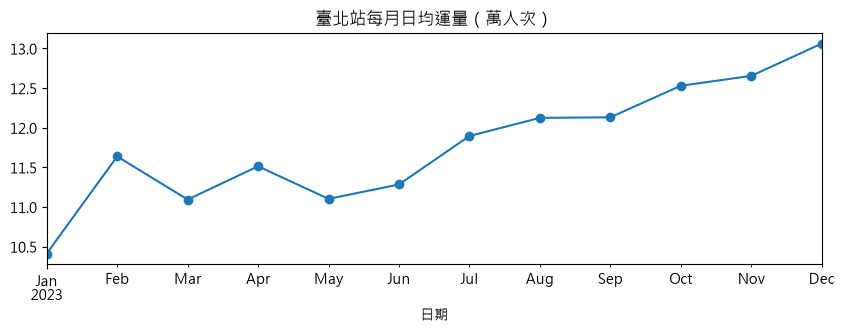

In [7]:
# 延伸 1
df['淨流量'] = df['gateInComingCnt'] - df['gateOutGoingCnt']
net = df.groupby('stationName')['淨流量'].mean().sort_values()
print('全年平均淨流量最負（出站多於進站）：\n', net.head(5).round(0))
print('\n全年平均淨流量最正（進站多於出站）：\n', net.tail(5).round(0))

# 延伸 2
wk_all = df.pivot_table(index='stationName', columns='假日', values='總運量', aggfunc='mean')
wk_all.columns = ['平日平均', '假日平均']
wk_all = wk_all[wk_all.mean(axis=1) >= 1000]
print('\n門檻 1,000 時的通勤站前 5 名：\n', (wk_all['平日平均'] / wk_all['假日平均']).nlargest(5).round(2))

# 延伸 3（以臺北站為例，換成你家附近的站名）
one = df[df['stationName'] == '臺北'].set_index('日期')['總運量'].resample('ME').mean()
(one / 10000).plot(marker='o', figsize=(10, 3), title='臺北站每月日均運量（萬人次）')
plt.show()